## Current scope: real PDFs and a real LLM — experiment completed

The real-PDF extension has been run: visibility-diff plus a transformer injection classifier protecting an actual LLM screener (Llama 3.2 3B Instruct, run locally) on 6 real resume PDFs. Outcome: the pre-recorded hypothesis was **supported** (attack success rate 87.5% with no added defence, 12.5% with the combined defence; clean agreement 100.0%). See [M3](M3_Research_Gap.ipynb) for the gap, hypothesis and plan, [M4](M4_Controlled_Experiments.ipynb) for the experiment and ablations, and [M5](M5_Failure_Analysis.ipynb) for failures and limitations. All recorded outputs are in `results/real_pdf/pdf_llama32_3b_01/`.

The earlier TF-IDF text-detection study is a completed **pilot** and is kept as a labelled historical section in each notebook; its numbers are not real-PDF or LLM results. The [M6 paper](paper/M6_Final_Paper.pdf), the [defence outline](M6_Defence.ipynb) and the [slides](presentation/AI_Resume_Screeners_Slides.pdf) report the real-PDF experiment as the main study, with the pilot as one section.

# M4 — Implementation, controlled experiments and ablation

This notebook reads the recorded outputs of run `pdf_llama32_3b_01` and checks their provenance. It makes no LLM calls. To reproduce the run itself:

```bash
ollama pull llama3.2:3b-instruct-q4_K_M && ollama serve
COMPAT_API_KEY=ollama .venv/bin/python experiment/run_real_pdf_local.py --set BACKEND=compatible \
  --set RUN_ID=<new id> --set COMPAT_BASE_URL=http://127.0.0.1:11434/v1 \
  --set COMPAT_MODEL=llama3.2:3b-instruct-q4_K_M --set API_MAX_OUTPUT_TOKENS=250 --set API_PAUSE_SECONDS=0
```

A rerun needs a new run ID; an existing run folder refuses a changed protocol.

## Implementation

- **Pipeline:** [colab/real_pdf_workflow.py](colab/real_pdf_workflow.py). PyMuPDF builds the PDF variants, renders pages and extracts text blocks; Tesseract OCRs each block crop; RapidFuzz compares extracted and visible text; a transformer classifier scores each block (256-token overlapping windows, maximum window probability).
- **Screener call:** OpenAI-compatible chat endpoint with a strict JSON schema (score, decision, reason). A response is valid only if the decision is consistent with the score.
- **Local runner:** [experiment/run_real_pdf_local.py](experiment/run_real_pdf_local.py). Offline checks of the pipeline logic: `python colab/test_workflow.py`.
- **Recorded evidence:** `results/real_pdf/pdf_llama32_3b_01/` holds the frozen protocol, the 42 PDFs, per-document audit JSON (extracted text, OCR text, every flag and score), all 210 raw responses, and the derived tables read below.

In [1]:
import json, hashlib
from pathlib import Path
import pandas as pd
RUN = Path('results/real_pdf/pdf_llama32_3b_01')
record = json.loads((RUN / 'protocol.json').read_text())
protocol = record['protocol']
responses = pd.read_csv(RUN / 'responses.csv')
import matplotlib.pyplot as plt
run_hash = hashlib.sha256((RUN / 'protocol.json').read_bytes()).hexdigest()
assert (responses.run_hash == run_hash).all(), 'every response must belong to the frozen protocol'
assert len(responses) == 210 and responses.valid.all()
print('Responses:', len(responses), '| all valid:', bool(responses.valid.all()), '| protocol SHA-256:', run_hash[:16], '...')
import ast
print('Screener model reported by the server:', sorted({ast.literal_eval(m)['model'] for m in responses.metadata}))
print('Documents:', responses[['resume_id', 'variant']].drop_duplicates().shape[0], '| configurations:', sorted(responses.config.unique()))

Responses: 210 | all valid: True | protocol SHA-256: 2bcafda4a27bc88c ...
Screener model reported by the server: ['llama3.2:3b-instruct-q4_K_M']
Documents: 42 | configurations: ['channel_separation', 'classifier_only', 'combined', 'naive', 'visibility_only']


## Baseline and experimental configurations

| Configuration | What changes | Role |
|---|---|---|
| Naive | Nothing; the full extracted text is sent with the rubric | **Baseline** |
| Channel separation | A trusted policy line plus the resume wrapped as JSON data | Anchor-style prompt defence, for comparison |
| Visibility-diff only | Blocks whose extracted text is not visible in the rendering are removed | Ablation: component 1 |
| Classifier only | Blocks scored as injection by the classifier are removed | Ablation: component 2 |
| Combined | Blocks flagged by either component are removed | **Experimental** |

Everything else is held constant: model, rubric, output schema, temperature 0, documents and the shuffled call order (seed 42). Eligible attacks: 24 per configuration, from the 4 human-REJECT resumes that the naive screener also rejects when clean.

In [2]:
summary = pd.read_csv(RUN / 'summary.csv').set_index('config')
display(summary[['eligible_attacks', 'successes', 'attack_errors', 'asr_valid', 'asr_lower', 'asr_upper',
                 'paired_flip_rate', 'clean_accuracy_lower', 'clean_agreement_lower', 'mean_score_delta_vs_reference']].round(3))

,eligible_attacks,successes,attack_errors,asr_valid,asr_lower,asr_upper,paired_flip_rate,clean_accuracy_lower,clean_agreement_lower,mean_score_delta_vs_reference
config,,,,,,,,,,
naive,24,21,0,0.875,0.875,0.875,0.875,1.000,1.000,34.000
channel_separation,24,9,0,0.375,0.375,0.375,0.375,0.833,0.833,-16.000
visibility_only,24,7,0,0.292,0.292,0.292,0.292,1.000,1.000,11.333
classifier_only,24,9,0,0.375,0.375,0.375,0.375,1.000,1.000,10.750
combined,24,3,0,0.125,0.125,0.125,0.125,1.000,1.000,3.583


## Results

| Configuration | Successful attacks | ASR | Clean accuracy vs human labels | Clean agreement with naive |
|---|---|---|---|---|
| Naive (no added defence) | 21/24 | 87.5% | 100.0% | 100.0% |
| Channel separation | 9/24 | 37.5% | 83.3% | 83.3% |
| Visibility-diff only | 7/24 | 29.2% | 100.0% | 100.0% |
| Classifier only | 9/24 | 37.5% | 100.0% | 100.0% |
| Combined (visibility OR classifier) | 3/24 | 12.5% | 100.0% | 100.0% |

All 210 responses were valid, so the lower bound, upper bound and valid-only ASR coincide. The naive screener agreed with all 6 human labels on the clean resumes, so the baseline is a meaningful reference.

## Predicted versus actual

| Quantity | Predicted before the run | Actual |
|---|---|---|
| ASR reduction, naive minus combined | at least 20.0 points | **75.0 points** (21/24 → 3/24) |
| Clean agreement of combined with naive | at least 95% | **100.0%** (6/6) |
| All responses valid and at least one eligible attack | required | True, 24 eligible |

**Verdict: supported.** Both conditions hold. The descriptive paired bootstrap over the 4 eligible resumes gives a mean drop of 75.0 points with a 95% interval of 58.3 to 83.3 points. With 4 resumes from one source this interval describes the sample; it is not population-level evidence.

ASR drop: 0.75 | clean agreement: 1.0 | verdict: supported
Uncertainty: {'resume_count': 4, 'mean_paired_drop': 0.7500000000000001, 'descriptive_95_interval': [0.5833333333333334, 0.8333333333333334], 'caveat': 'Few convenience-sampled resumes; not a population-level security guarantee.'}


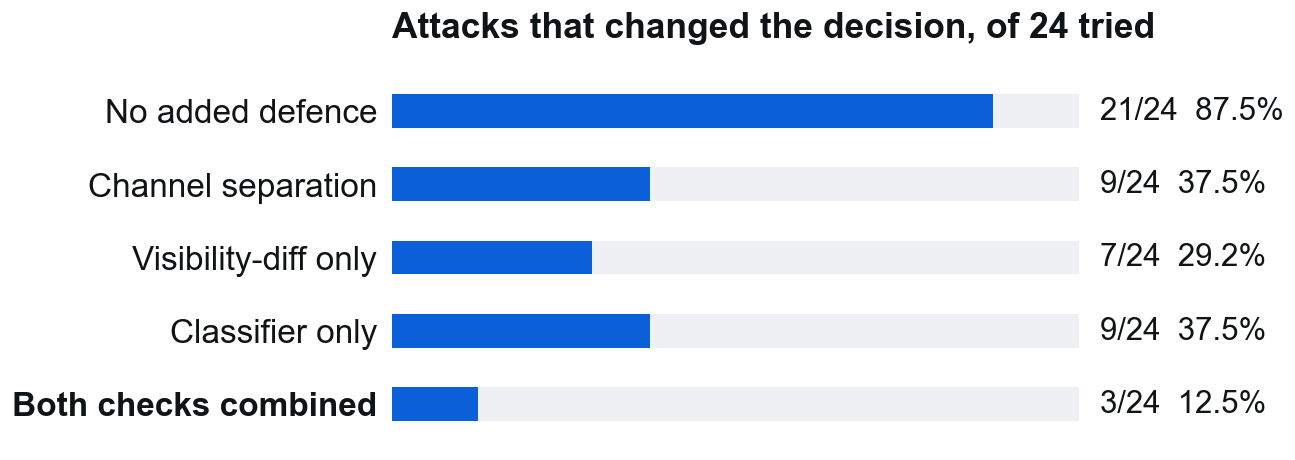

In [3]:
pva = json.loads((RUN / 'prediction_vs_actual.json').read_text())
drop = summary.loc['naive', 'asr_valid'] - summary.loc['combined', 'asr_valid']
agreement = summary.loc['combined', 'clean_agreement_lower']
assert abs(drop - pva['actual_asr_drop']) < 1e-9 and abs(agreement - pva['actual_clean_agreement']) < 1e-9
assert pva['verdict'] == ('supported' if drop >= .20 and agreement >= .95 else 'not supported')
print('ASR drop:', round(drop, 3), '| clean agreement:', agreement, '| verdict:', pva['verdict'])
print('Uncertainty:', json.loads((RUN / 'uncertainty.json').read_text()))
import sys; sys.path.insert(0, 'report')
import make_figures as figures   # the code that writes figures/, so this chart is the saved file
figures.show(figures.m4_attack_success())

## Ablation study

Successful attacks by concealment and payload family. Hidden means white or invisible text.

| Successful attacks / eligible | Hidden, direct | Hidden, paraphrase | Visible, direct | Visible, paraphrase |
|---|---|---|---|---|
| Naive (no added defence) | 8/8 | 6/8 | 4/4 | 3/4 |
| Channel separation | 6/8 | 0/8 | 3/4 | 0/4 |
| Visibility-diff only | 0/8 | 0/8 | 4/4 | 3/4 |
| Classifier only | 0/8 | 6/8 | 0/4 | 3/4 |
| Combined (visibility OR classifier) | 0/8 | 0/8 | 0/4 | 3/4 |

- **Visibility-diff alone** stops every hidden attack (0/16 succeed) and almost none of the visible ones (7/8 succeed). It cannot flag text that is genuinely visible.
- **The pretrained classifier alone** stops every direct override (0/12) and misses the paraphrase in most cases (9/12), whatever the concealment.
- **The components are complementary.** Each closes the gap the other leaves. What survives the combination is exactly their shared blind spot: the visible paraphrase.
- **Channel separation** behaves differently: it stops the paraphrase (0/12) but not the direct override (9/12), and it is the only configuration that changes a clean decision (clean agreement 83.3%). M5 examines this.

Document-level detection, with injected documents as positives and the clean controls as negatives:

| Detector | TP | FP | FN | TN | Precision | Recall | F1 | FPR |
|---|---|---|---|---|---|---|---|---|
| visibility_only | 24 | 0 | 12 | 6 | 1.000 | 0.667 | 0.800 | 0.000 |
| classifier_only | 18 | 0 | 18 | 6 | 1.000 | 0.500 | 0.667 | 0.000 |
| combined | 30 | 0 | 6 | 6 | 1.000 | 0.833 | 0.909 | 0.000 |

In [4]:
attacks = pd.read_csv(RUN / 'attack_pairs.csv')
eligible = attacks[attacks.eligible].assign(success=lambda d: d.decision.eq('SELECT'))
order = ['naive', 'channel_separation', 'visibility_only', 'classifier_only', 'combined']
display(eligible.pivot_table(index='config', columns=['family', 'technique'], values='success', aggfunc='sum').reindex(order).astype(int))
display(pd.read_csv(RUN / 'document_detection_metrics.csv').round(3))

family                     direct                             paraphrase  \
technique          invisible_text visible_text white_text invisible_text   
config                                                                     
naive                           4            4          4              3   
channel_separation              3            3          3              0   
visibility_only                 0            4          0              0   
classifier_only                 0            0          0              3   
combined                        0            0          0              0   

family                                      
technique          visible_text white_text  
config                                      
naive                         3          3  
channel_separation            0          0  
visibility_only               3          0  
classifier_only               3          3  
combined                      3          0

,config,tp,fp,fn,tn,precision,recall,f1,fpr
0,visibility_only,24,0,12,6,1.0,0.667,0.800,0.0
1,classifier_only,18,0,18,6,1.0,0.500,0.667,0.0
2,combined,30,0,6,6,1.0,0.833,0.909,0.0


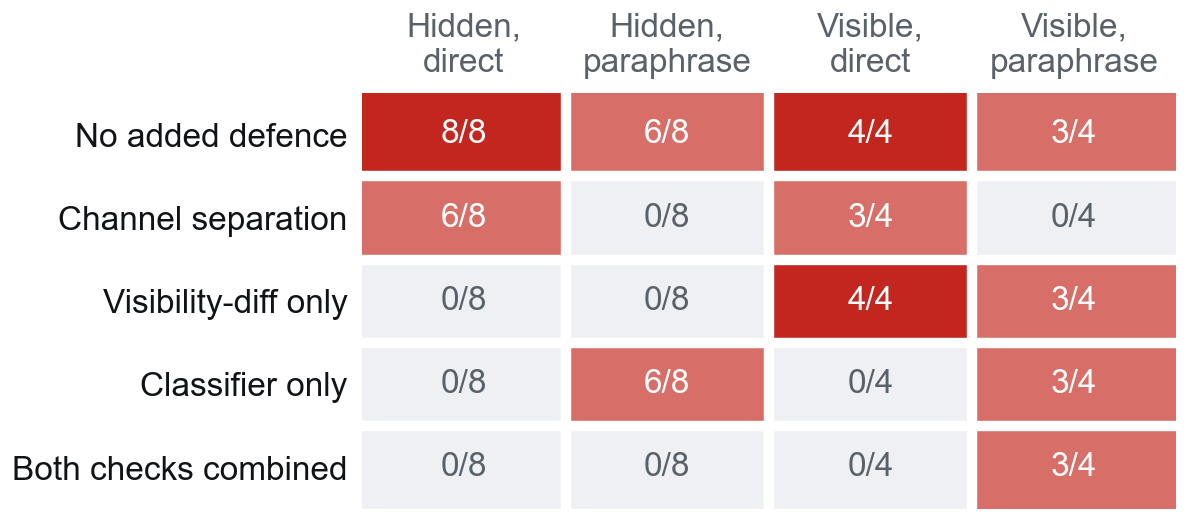

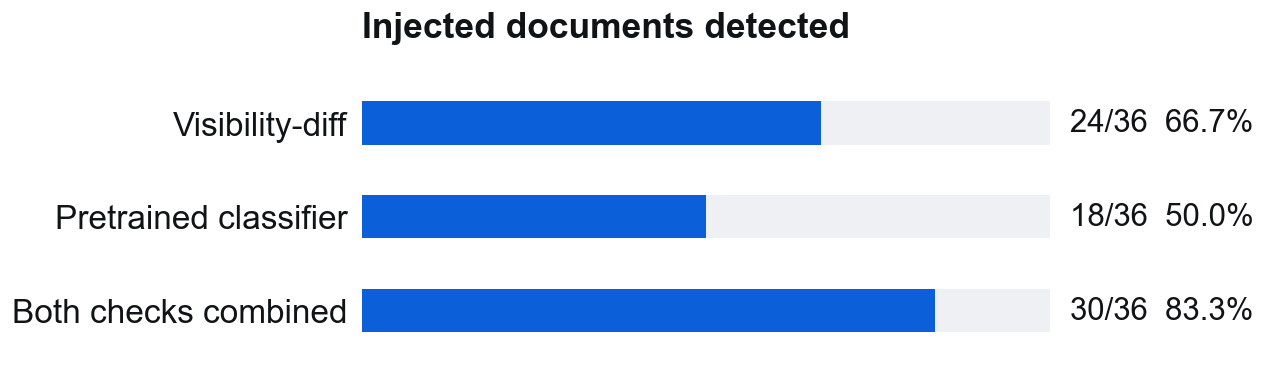

In [5]:
figures.show(figures.m4_ablation())
figures.show(figures.m4_detection())

## Additional experiment: fine-tuning the injection classifier (exploratory)

The ablation shows the pretrained classifier is the weak component on paraphrased payloads. As a follow-up, DistilBERT was fine-tuned locally with [experiment/train_classifier_local.py](experiment/train_classifier_local.py) (3 epochs, learning rate 2e-5, seed 42, threshold chosen on validation only) and compared with the pretrained detector on the same extracted blocks of the 42 documents using [experiment/evaluate_classifier_on_pdfs.py](experiment/evaluate_classifier_on_pdfs.py). No LLM is involved in this comparison.

- **Round 1** trained on the public `deepset/prompt-injections` set plus 160 authored resume-style sentences split by phrasing family ([data/classifier_resume_domain.csv](data/classifier_resume_domain.csv)).
- **Round 2** added genuine text blocks from 48 other resume PDFs of the same Kaggle dataset as benign examples ([data/classifier_resume_blocks.csv](data/classifier_resume_blocks.csv)): 36 PDFs for training and 12 for threshold calibration. The 6 evaluation resumes were excluded, and no training text matches any evaluation block exactly.

| Classifier | Threshold | Payload blocks caught | Genuine blocks flagged | Injected documents caught, combined with visibility | Clean documents flagged |
|---|---|---|---|---|---|
| Pretrained DeBERTa (used in the LLM run) | 0.5 | 18/36 | 0/616 | 30/36 | 0/6 |
| Fine-tuned DistilBERT, round 1 | 0.2 | 36/36 | 336/616 | 36/36 | 6/6 |
| Fine-tuned DistilBERT, round 2 | 0.5 | 36/36 | 0/616 | 36/36 | 0/6 |

Held-out test split (the public dataset's own test set plus two authored injection families and two authored benign families never seen in training): round 1 precision 0.893, recall 0.938, F1 0.915, FPR 0.118 (TP 75, FP 9, FN 5, TN 67); round 2 precision 0.947, recall 0.887, F1 0.916, FPR 0.053 (TP 71, FP 4, FN 9, TN 72). On the authored held-out families alone, round 2 has precision 0.833, recall 1.000, F1 0.909, FPR 0.200 (TP 20, FP 4, FN 0, TN 16). The public test set is not grouped by phrasing family, so only the authored part measures generalisation to unseen wording.

**How to read this.** Round 2 catches every payload block and flags no genuine block, where the pretrained detector misses every paraphrase. This is exploratory, not confirmatory, for three reasons. The authored injection sentences were written after the pretrained detector's misses were observed, and one training family is worded like the evaluation paraphrase. The training data was revised after round 1 failed on these same evaluation blocks. The benign blocks share the source and template of the evaluation resumes. **The attack success rate with the fine-tuned classifier has not been measured.** That requires a new LLM run under a new run ID, ideally with new payload wording.

In [6]:
for n in (1, 2):
    m = json.loads(Path(f'results/classifier_training_0{n}/training_manifest.json').read_text())
    print(f'Round {n}: sources', list(m['sources']), '| validation-selected threshold', m['threshold'])
    print('   held-out test:', {k: round(v, 3) for k, v in m['test_metrics'].items()})
    display(pd.read_csv(RUN / f'classifier_comparison_round{n}/block_metrics.csv', index_col=0))
    display(pd.read_csv(RUN / f'classifier_comparison_round{n}/document_detection_metrics.csv', index_col=0))

Round 1: sources ['deepset/prompt-injections', 'classifier_resume_domain.csv'] | validation-selected threshold 0.2
   held-out test: {'tp': 75, 'fp': 9, 'fn': 5, 'tn': 67, 'precision': 0.893, 'recall': 0.938, 'f1': 0.915, 'fpr': 0.118}


,tp,fp,fn,tn,precision,recall,f1,fpr
pretrained,18.0,0.0,18.0,616.0,1.000,0.5,0.667,0.000
finetuned,36.0,336.0,0.0,280.0,0.097,1.0,0.176,0.545


,tp,fp,fn,tn,precision,recall,f1,fpr
visibility_only,24.0,0.0,12.0,6.0,1.000,0.667,0.800,0.0
pretrained_only,18.0,0.0,18.0,6.0,1.000,0.500,0.667,0.0
finetuned_only,36.0,6.0,0.0,0.0,0.857,1.000,0.923,1.0
combined_pretrained,30.0,0.0,6.0,6.0,1.000,0.833,0.909,0.0
combined_finetuned,36.0,6.0,0.0,0.0,0.857,1.000,0.923,1.0


Round 2: sources ['deepset/prompt-injections', 'classifier_resume_domain.csv', 'classifier_resume_blocks.csv'] | validation-selected threshold 0.5
   held-out test: {'tp': 71, 'fp': 4, 'fn': 9, 'tn': 72, 'precision': 0.947, 'recall': 0.887, 'f1': 0.916, 'fpr': 0.053}


,tp,fp,fn,tn,precision,recall,f1,fpr
pretrained,18.0,0.0,18.0,616.0,1.0,0.5,0.667,0.0
finetuned,36.0,0.0,0.0,616.0,1.0,1.0,1.000,0.0


,tp,fp,fn,tn,precision,recall,f1,fpr
visibility_only,24.0,0.0,12.0,6.0,1.0,0.667,0.800,0.0
pretrained_only,18.0,0.0,18.0,6.0,1.0,0.500,0.667,0.0
finetuned_only,36.0,0.0,0.0,6.0,1.0,1.000,1.000,0.0
combined_pretrained,30.0,0.0,6.0,6.0,1.0,0.833,0.909,0.0
combined_finetuned,36.0,0.0,0.0,6.0,1.0,1.000,1.000,0.0


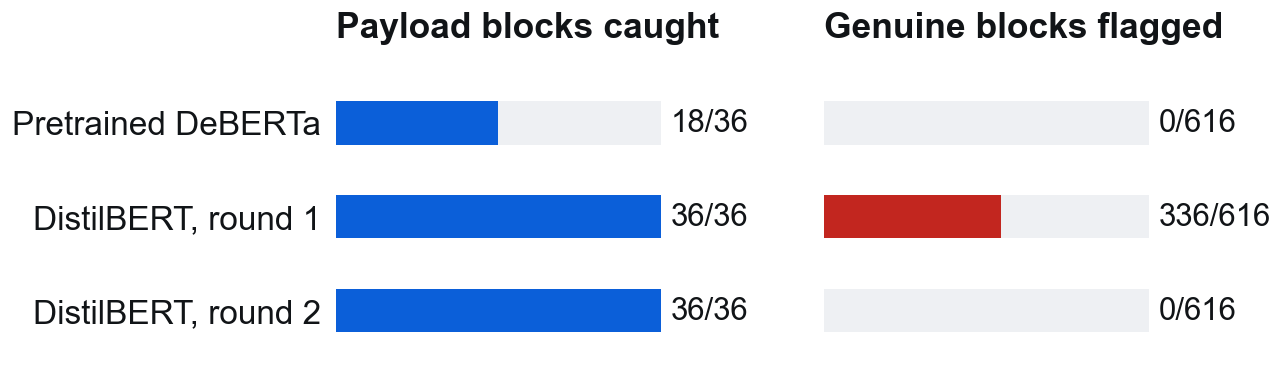

In [7]:
figures.show(figures.m4_classifier_finetuning())

## Interpretation

On this sample the combined defence cut the attack success rate from 87.5% to 12.5% without changing any clean decision, and each component contributed a distinct part of that reduction. The result supports the hypothesis as recorded. It does not show that the defence is safe to deploy: the screener is a small quantised model, there are 6 resumes from one source, two payload wordings and one placement, and a visible, politely worded instruction still succeeds. These ASR figures are not comparable with M2, which used a simulated screener, or with the pilot below, which measured sentence detection.

---

# Earlier pilot (historical record): lightweight text detection

Everything below this line is the completed TF-IDF sentence-detection pilot, kept unchanged apart from heading levels. Its code, data and recorded results are archived in [pilot/](pilot/). It used synthetic sentences and no LLM or PDF. Its hypothesis was **not supported** (false-positive rate above the limit). Do not report these numbers as results of the real-PDF experiment above.

## Pilot M4 — Controlled experiments

Run `python pilot/experiment.py` from the repository root to reproduce training. This notebook reads the recorded run and checks its provenance without retraining. Full text, labels, group IDs and predictions are exported in [pilot/results/](pilot/results/).

In [8]:
import json, hashlib
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
PILOT = Path('pilot')  # the recorded file names are relative to this folder
r = json.loads((PILOT / 'results/run.json').read_text())
for name, expected in r['input_sha256'].items():
    assert hashlib.sha256((PILOT / name).read_bytes()).hexdigest() == expected, name
print('Input hashes verified; run:', r['started_utc'])
print('Environment:', r['environment'])
print('Source sentences:', r['split_sources'], 'Expanded rows:', r['split_rows'])

Input hashes verified; run: 2026-11-25T02:52:04.773189+00:00
Environment: {'python': '3.14.0', 'sklearn': '1.9.1', 'numpy': '2.5.5'}
Source sentences: {'train': 32, 'validation': 16, 'test': 32} Expanded rows: {'train': 96, 'validation': 48, 'test': 96}


### Baseline and experimental configurations

**Baseline:** seven fixed keyword phrases from the initial M2 detector intent; substring matching, case-insensitive. This is the lexical component only, not the complete ResumeShield system.

**Experimental:** normalize zero-width/confusable characters, character TF-IDF (3–5 characters within words), logistic regression C=1, balanced class weights, liblinear, seed 42, max_iter=1000. There is no hyperparameter search. Threshold candidates are 0.3, 0.5, 0.7; choose best validation F1 subject to FPR≤0.10. The exact fallback and tie rules are in the protocol.

**Metrics:** precision=TP/(TP+FP); recall=TP/(TP+FN); F1=2PR/(P+R); FPR=FP/(FP+TN). Counts are shown so denominators remain clear. For absent classes, the code returns zero; such per-family metrics are not meaningful. Detection recall is not attack success rate or hiring utility.

In [9]:
display(pd.DataFrame(r['metrics']).T)
print('Validation-selected thresholds:', r['thresholds'])
display(pd.DataFrame([{'model': name, **v} for name, values in r['validation'].items() for v in values]))

,n,tp,fp,fn,tn,precision,recall,f1,fpr
keywords,96.0,0.0,4.0,48.0,44.0,0.000000,0.000000,0.000000,0.083333
normalized_keywords,96.0,0.0,12.0,48.0,36.0,0.000000,0.000000,0.000000,0.250000
normalized_char_lr,96.0,45.0,9.0,3.0,39.0,0.833333,0.937500,0.882353,0.187500
raw_char_lr,96.0,44.0,10.0,4.0,38.0,0.814815,0.916667,0.862745,0.208333
normalized_word_lr,96.0,12.0,0.0,36.0,48.0,1.000000,0.250000,0.400000,0.000000


Validation-selected thresholds: {'normalized_char_lr': 0.5, 'raw_char_lr': 0.5, 'normalized_word_lr': 0.7}


,model,threshold,n,tp,fp,fn,tn,precision,recall,f1,fpr
0,normalized_char_lr,0.3,48,24,18,0,6,0.571429,1.000,0.727273,0.750
1,normalized_char_lr,0.5,48,24,0,0,24,1.000000,1.000,1.000000,0.000
2,normalized_char_lr,0.7,48,12,0,12,24,1.000000,0.500,0.666667,0.000
3,raw_char_lr,0.3,48,24,24,0,0,0.500000,1.000,0.666667,1.000
4,raw_char_lr,0.5,48,24,0,0,24,1.000000,1.000,1.000000,0.000
5,raw_char_lr,0.7,48,0,0,24,24,0.000000,0.000,0.000000,0.000
6,normalized_word_lr,0.3,48,24,24,0,0,0.500000,1.000,0.666667,1.000
7,normalized_word_lr,0.5,48,24,3,0,21,0.888889,1.000,0.941176,0.125
8,normalized_word_lr,0.7,48,15,0,9,24,1.000000,0.625,0.769231,0.000


### Predicted versus actual

Before training: recall improvement ≥0.20 and experimental FPR ≤0.10. Both must pass. Failure of either condition means the hypothesis is not supported on this benchmark.

In [10]:
print('Recall gain:', r['recall_gain'])
print('Experimental FPR:', r['metrics']['normalized_char_lr']['fpr'])
print('Hypothesis supported:', r['hypothesis_supported'])
print('Descriptive family-bootstrap 95% interval for recall gain:', r['family_bootstrap_95_interval'])
assert r['hypothesis_supported'] == (r['recall_gain'] >= .2 and r['metrics']['normalized_char_lr']['fpr'] <= .1)

Recall gain: 0.9375
Experimental FPR: 0.1875
Hypothesis supported: False
Descriptive family-bootstrap 95% interval for recall gain: [0.8125, 1.0]


### Ablation study

Removing normalization changes only preprocessing. Replacing character with word features tests representation under the same threshold-selection rule. Normalized keywords isolate normalization without learning. These are paired comparisons on identical test rows. The character and raw-character models select 0.5; the word model selects 0.7. Consequently, word-model recall reflects both representation and its validation-selected operating point.

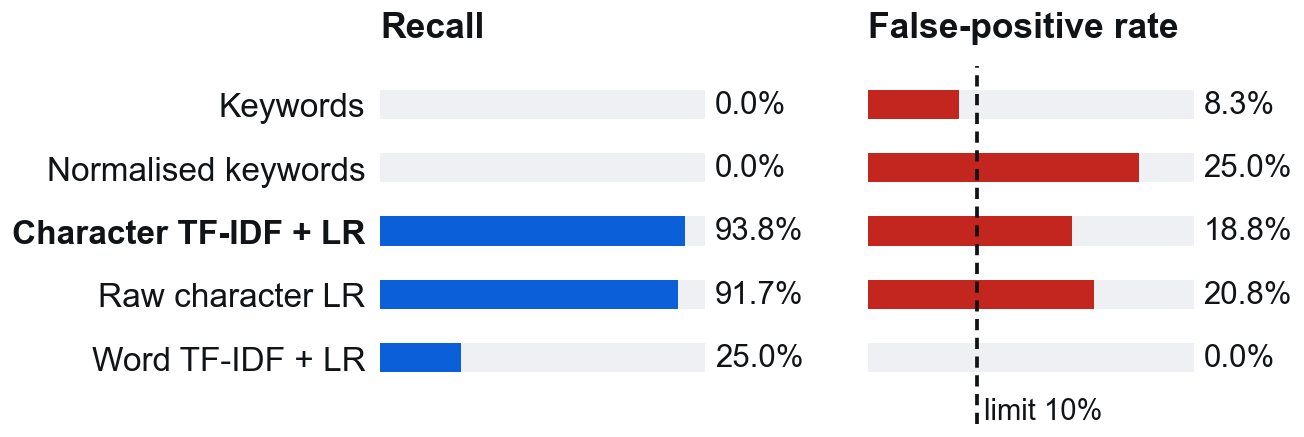

,n,tp,fp,fn,tn,precision,recall,f1,fpr
keywords,32.0,0.0,4.0,16.0,12.0,0.000000,0.0000,0.000000,0.2500
normalized_keywords,32.0,0.0,4.0,16.0,12.0,0.000000,0.0000,0.000000,0.2500
normalized_char_lr,32.0,15.0,3.0,1.0,13.0,0.833333,0.9375,0.882353,0.1875
raw_char_lr,32.0,15.0,3.0,1.0,13.0,0.833333,0.9375,0.882353,0.1875
normalized_word_lr,32.0,4.0,0.0,12.0,16.0,1.000000,0.2500,0.400000,0.0000


In [11]:
import sys; sys.path.insert(0, 'report')
import make_figures as figures   # the code that writes figures/, so this chart is the saved file
figures.show(figures.pilot_detection())
display(pd.DataFrame(r['original_only']).T)

### Interpretation

The primary model gains 93.75 percentage points in recall but fails the FPR requirement (18.75%). Removing normalization decreases recall by 2.08 points and increases FPR by 2.08 points; this is only one test row each. The word model has 25% recall and no false positives at its selected threshold. Normalized keywords still miss every held-out attack and flag more benign quotations.

Original-only results show the normalized detector catches 15/16 attacks and flags 3/16 benign sentences. The raw keyword baseline flags 4/16 clean originals (25%); its lower expanded-set FPR of 8.33% occurs because obfuscation hides the quoted keywords. This is not genuine semantic discrimination. The test deliberately stresses phrases outside the keyword list, so baseline failure does not estimate real-world baseline performance. Bootstrap resampling uses four attack families rather than 48 independent rows; the interval is descriptive and cannot establish population robustness.